In [1]:
!unzip jsonFiles.zip

Archive:  jsonFiles.zip
   creating: jsonFiles/
   creating: jsonFiles/json_3/
  inflating: jsonFiles/json_3/model_3_rmsprop.json  
  inflating: jsonFiles/json_3/model_3_adagrad.json  
  inflating: jsonFiles/json_3/model_3_adam.json  
  inflating: jsonFiles/json_3/model_3_sgd.json  
  inflating: jsonFiles/json_3/model_3_sgd_general_delta.json  
  inflating: jsonFiles/json_3/model_3_sgd_nag.json  
  inflating: jsonFiles/json_3/model_3_vanillaGD.json  
   creating: jsonFiles/json_4/
  inflating: jsonFiles/json_4/model_4_rmsprop.json  
  inflating: jsonFiles/json_4/model_4_adagrad.json  
  inflating: jsonFiles/json_4/model_4_adam.json  
  inflating: jsonFiles/json_4/model_4_sgd.json  
  inflating: jsonFiles/json_4/model_4_sgd_general_delta.json  
  inflating: jsonFiles/json_4/model_4_sgd_nag.json  
  inflating: jsonFiles/json_4/model_4_vanillaGD.json  
   creating: jsonFiles/json_5/
  inflating: jsonFiles/json_5/model_5_vanillaGD.json  
  inflating: jsonFiles/json_5/model_5_sgd.json  
  i

In [19]:
!unzip Group_16.zip

Streaming output truncated to the last 5000 lines.
  inflating: Group_16/train/6/img_21392.jpg  
  inflating: Group_16/train/6/img_2988.jpg  
  inflating: Group_16/train/6/img_16349.jpg  
  inflating: Group_16/train/6/img_5021.jpg  
  inflating: Group_16/train/6/img_21025.jpg  
  inflating: Group_16/train/6/img_21219.jpg  
  inflating: Group_16/train/6/img_23580.jpg  
  inflating: Group_16/train/6/img_18021.jpg  
  inflating: Group_16/train/6/img_10303.jpg  
  inflating: Group_16/train/6/img_21326.jpg  
  inflating: Group_16/train/6/img_12943.jpg  
  inflating: Group_16/train/6/img_18356.jpg  
  inflating: Group_16/train/6/img_19625.jpg  
  inflating: Group_16/train/6/img_26881.jpg  
  inflating: Group_16/train/6/img_23515.jpg  
  inflating: Group_16/train/6/img_31028.jpg  
  inflating: Group_16/train/6/img_16346.jpg  
  inflating: Group_16/train/6/img_12856.jpg  
  inflating: Group_16/train/6/img_11917.jpg  
  inflating: Group_16/train/6/img_25543.jpg  
  inflating: Group_16/train/6/i

In [47]:
!rm -rf training_error_plots

In [4]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# PATH TO JSON RESULT FOLDERS
# ============================================================

JSON_ROOT = "jsonFiles"
# ^ CHANGE THIS if your Kaggle dataset has a different path.


OPTIMIZER_NAMES = [
    "sgd",
    "vanillaGD",
    "sgd_general_delta",
    "sgd_nag",
    "adagrad",
    "rmsprop",
    "adam"
]

ARCHITECTURES_TO_LOAD = [3, 4, 5]


# ============================================================
# LOAD ALL JSON RESULTS
# ============================================================

all_results = {}

for architecture in ARCHITECTURES_TO_LOAD:

    all_results[architecture] = {}

    for optimizer_name in OPTIMIZER_NAMES:

        json_path = (
            f"{JSON_ROOT}/json_{architecture}/"
            f"model_{architecture}_{optimizer_name}.json"
        )

        if not os.path.exists(json_path):

            print(
                f"WARNING: File not found:\n"
                f"{json_path}"
            )

            continue

        with open(json_path, "r") as f:
            data = json.load(f)

        all_results[architecture][optimizer_name] = data


print("=" * 80)
print("JSON RESULT FILES LOADED")
print("=" * 80)

for architecture in all_results:

    print(
        f"Architecture {architecture}: "
        f"{len(all_results[architecture])}/7 optimizers loaded"
    )

print(all_results)

JSON RESULT FILES LOADED
Architecture 3: 7/7 optimizers loaded
Architecture 4: 7/7 optimizers loaded
Architecture 5: 7/7 optimizers loaded
{3: {'sgd': {'architecture': 3, 'activation': 'tanh', 'optimizer': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'threshold': 0.0001, 'epochs_limit': 10000, 'batch_size': 1, 'configurations': {'config_1': {'hidden_nodes': [128, 64, 32], 'initial_error': 1.6258579883650828, 'errors': [1.6258579883650828, 0.7415359845735888, 0.18871964756129445, 0.1483824734074801, 0.12943537365286262, 0.11672662482852567, 0.10581328145110326, 0.0979595940224993, 0.09089881292169087, 0.083346638078321, 0.07591408676598899, 0.070068085797589, 0.06538575290212413, 0.0606743340707713, 0.05588394144292121, 0.05183836391809328, 0.04876986223120213, 0.04491720154131731, 0.04194596394813589, 0.03926334863037656, 0.03638570321967856, 0.03421600707630364, 0.03145957573787227, 0.029005318525996394, 0.027043836148768253, 0.025175745829630804, 0.023218882745603502, 0.0217185414

In [5]:
# ============================================================
# CONVERGENCE EPOCH TABLE
# ============================================================

rows = []

for architecture in ARCHITECTURES_TO_LOAD:

    for optimizer_name in OPTIMIZER_NAMES:

        if optimizer_name not in all_results[architecture]:
            continue

        result = all_results[
            architecture
        ][
            optimizer_name
        ]

        for config_name, config_result in result[
            "configurations"
        ].items():

            rows.append({

                "Hidden Layers":
                    architecture,

                "Configuration":
                    config_name,

                "Neurons":
                    str(config_result["hidden_nodes"]),

                "Optimizer":
                    optimizer_name,

                "Convergence Epochs":
                    config_result["epochs"]
            })


convergence_df = pd.DataFrame(rows)

convergence_df = convergence_df.sort_values(
    [
        "Hidden Layers",
        "Configuration",
        "Optimizer"
    ]
)


display(convergence_df)

,Hidden Layers,Configuration,Neurons,Optimizer,Convergence Epochs
12,3,config_1,"[128, 64, 32]",adagrad,929
18,3,config_1,"[128, 64, 32]",adam,85
15,3,config_1,"[128, 64, 32]",rmsprop,116
0,3,config_1,"[128, 64, 32]",sgd,53
6,3,config_1,"[128, 64, 32]",sgd_general_delta,22
...,...,...,...,...,...
59,5,config_3,"[512, 256, 128, 64, 32]",rmsprop,79
44,5,config_3,"[512, 256, 128, 64, 32]",sgd,41
50,5,config_3,"[512, 256, 128, 64, 32]",sgd_general_delta,38
53,5,config_3,"[512, 256, 128, 64, 32]",sgd_nag,36


In [6]:
# ============================================================
# CONVERGENCE TABLE BY ARCHITECTURE + CONFIGURATION
# ============================================================

for architecture in ARCHITECTURES_TO_LOAD:

    architecture_df = convergence_df[
        convergence_df["Hidden Layers"] == architecture
    ]

    pivot_df = architecture_df.pivot(
        index=["Configuration", "Neurons"],
        columns="Optimizer",
        values="Convergence Epochs"
    )

    print("\n")
    print("=" * 100)
    print(
        f"ARCHITECTURE: {architecture} HIDDEN LAYERS"
    )
    print("=" * 100)

    display(pivot_df)



ARCHITECTURE: 3 HIDDEN LAYERS


,Optimizer,adagrad,adam,rmsprop,sgd,sgd_general_delta,sgd_nag,vanillaGD
Configuration,Neurons,,,,,,,
config_1,"[128, 64, 32]",929,85,116,53,22,24,3
config_2,"[256, 128, 64]",610,78,154,41,25,16,3
config_3,"[512, 256, 128]",345,54,261,44,24,24,4838




ARCHITECTURE: 4 HIDDEN LAYERS


,Optimizer,adagrad,adam,rmsprop,sgd,sgd_general_delta,sgd_nag,vanillaGD
Configuration,Neurons,,,,,,,
config_1,"[128, 64, 32, 16]",1872,126,50,31,25,28,3
config_2,"[256, 128, 64, 32]",915,62,155,57,27,28,3
config_3,"[512, 256, 128, 64]",284,41,134,64,29,30,3




ARCHITECTURE: 5 HIDDEN LAYERS


,Optimizer,adagrad,adam,rmsprop,sgd,sgd_general_delta,sgd_nag,vanillaGD
Configuration,Neurons,,,,,,,
config_1,"[128, 64, 32, 16, 8]",2200,100,254,31,46,8,1
config_2,"[256, 128, 64, 32, 16]",1785,22,54,52,28,30,1
config_3,"[512, 256, 128, 64, 32]",309,9,79,41,38,36,1


In [39]:
# ============================================================
# VERIFY INITIAL ERROR IS IDENTICAL ACROSS OPTIMIZERS
# ============================================================

ARCHITECTURES_TO_LOAD = [3, 4, 5]
ARCHITECTURES = {
    3: {
        "config_1": [128, 64, 32],
        "config_2": [256, 128, 64],
        "config_3": [512, 256, 128]
    },
    4: {
        "config_1": [128, 64, 32, 16],
        "config_2": [256, 128, 64, 32],
        "config_3": [512, 256, 128, 64]
    },
    5: {
        "config_1": [128, 64, 32, 16, 8],
        "config_2": [256, 128, 64, 32, 16],
        "config_3": [512, 256, 128, 64, 32]
    }
}

print("=" * 100)
print("INITIAL ERROR CONSISTENCY CHECK")
print("=" * 100)


for architecture in ARCHITECTURES_TO_LOAD:

    print(
        f"\nArchitecture: "
        f"{architecture} hidden layers"
    )

    for config_name in ARCHITECTURES[
        architecture
    ]:

        print(
            f"\n{config_name}"
        )

        initial_errors = {}

        for optimizer_name in OPTIMIZER_NAMES:

            if optimizer_name not in all_results[
                architecture
            ]:
                continue


            result = all_results[
                architecture
            ][
                optimizer_name
            ]


            if config_name not in result[
                "configurations"
            ]:
                continue


            initial_error = result[
                "configurations"
            ][
                config_name
            ][
                "initial_error"
            ]


            initial_errors[
                optimizer_name
            ] = initial_error


        for optimizer_name, error in initial_errors.items():

            print(
                f"{optimizer_name:20s}: "
                f"{error:.10f}"
            )


        # ----------------------------------------------------
        # Check maximum difference
        # ----------------------------------------------------

        if len(initial_errors) > 1:

            values = list(
                initial_errors.values()
            )

            max_difference = (
                max(values) -
                min(values)
            )

            print(
                f"Maximum difference: "
                f"{max_difference:.12e}"
            )

            if max_difference == 0:

                print(
                    f"\n{architecture}\n"
                    "✓ IDENTICAL"
                )

            elif max_difference < 1e-7:

                print(
                    "✓ Effectively identical "
                    "(floating-point precision)"
                )

            else:

                print(
                    "⚠ WARNING: Initial errors differ!"
                )

INITIAL ERROR CONSISTENCY CHECK

Architecture: 3 hidden layers

config_1
sgd                 : 1.6258579884
vanillaGD           : 1.6258579884
sgd_general_delta   : 1.6258579884
sgd_nag             : 1.6258579884
adagrad             : 1.6258579884
rmsprop             : 1.6258579884
adam                : 1.6258579884
Maximum difference: 0.000000000000e+00

3
✓ IDENTICAL

config_2
sgd                 : 1.6126577221
vanillaGD           : 1.6126577221
sgd_general_delta   : 1.6126577221
sgd_nag             : 1.6126577221
adagrad             : 1.6126577221
rmsprop             : 1.6126577221
adam                : 1.6126577221
Maximum difference: 0.000000000000e+00

3
✓ IDENTICAL

config_3
sgd                 : 1.6116886357
vanillaGD           : 1.6116886357
sgd_general_delta   : 1.6116886357
sgd_nag             : 1.6116886357
adagrad             : 1.6116886357
rmsprop             : 1.6116886357
adam                : 1.6116886357
Maximum difference: 0.000000000000e+00

3
✓ IDENTICAL

Architect

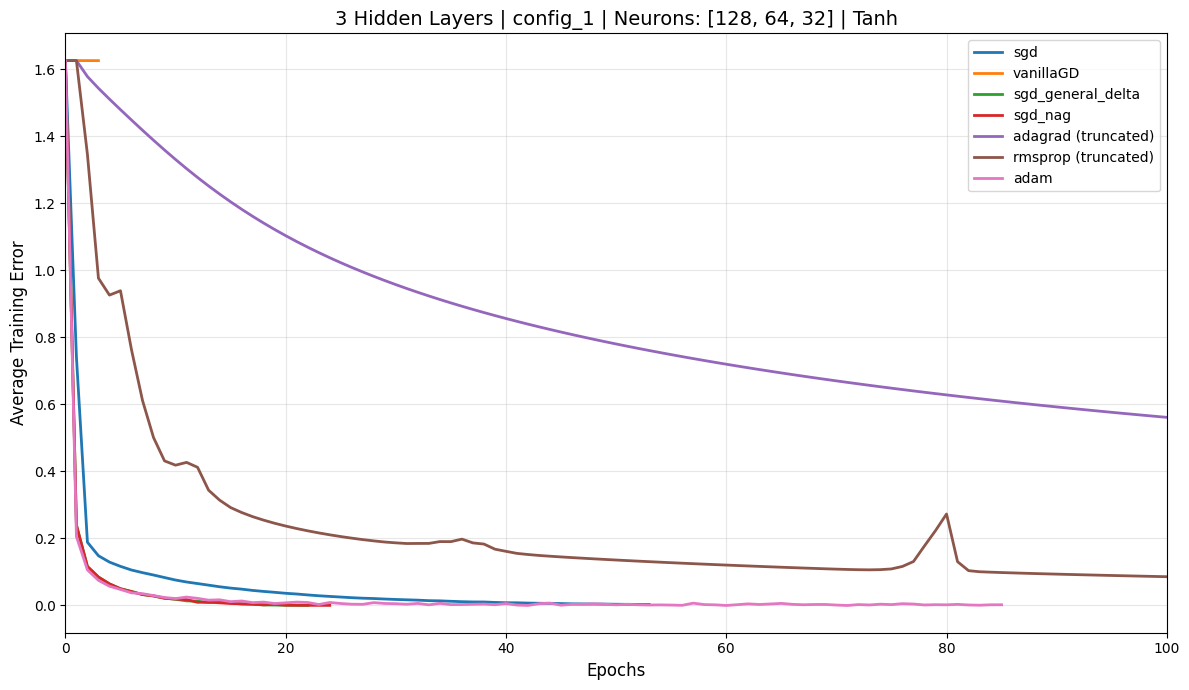

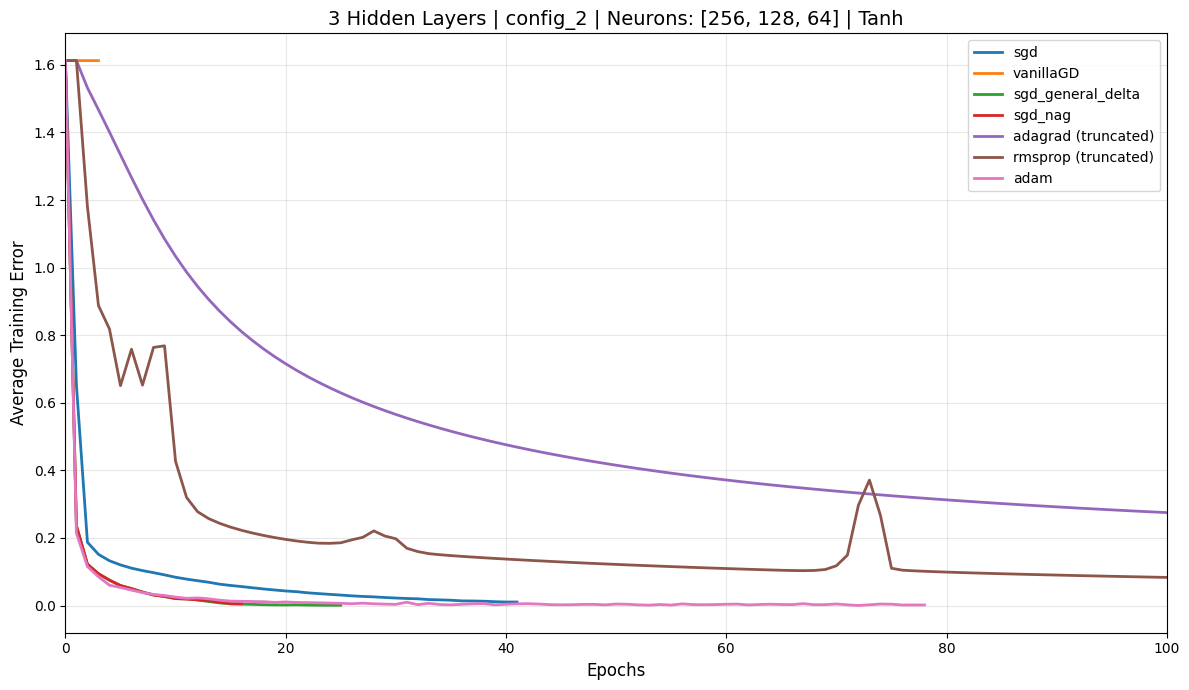

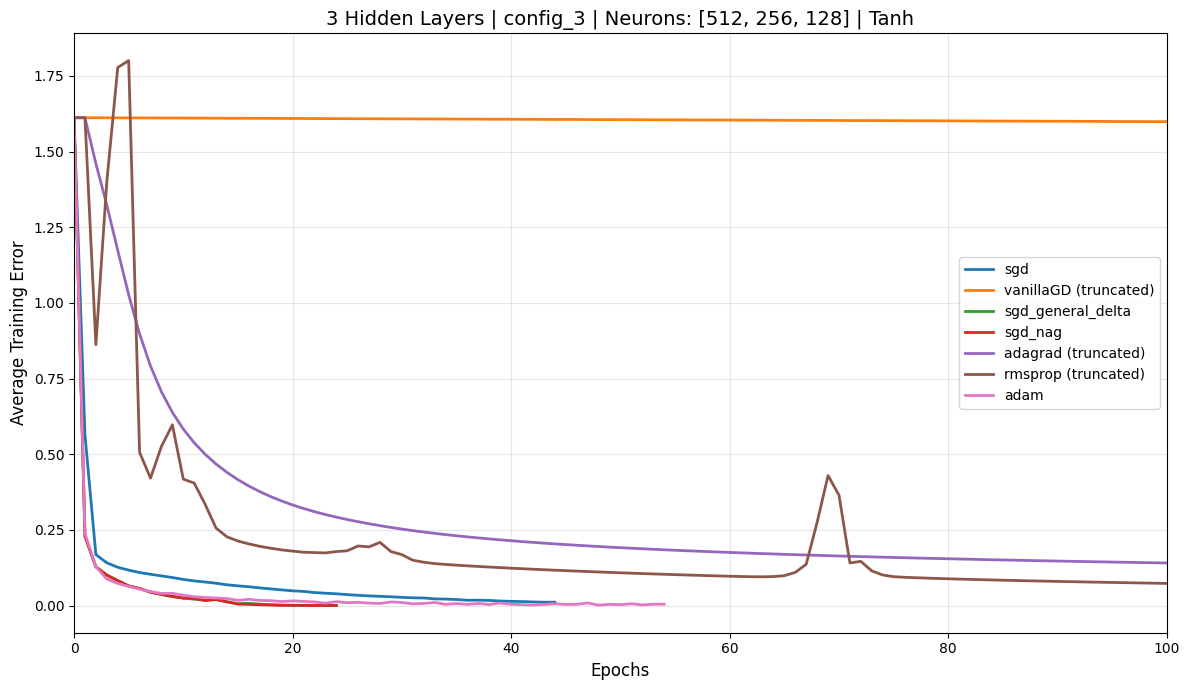

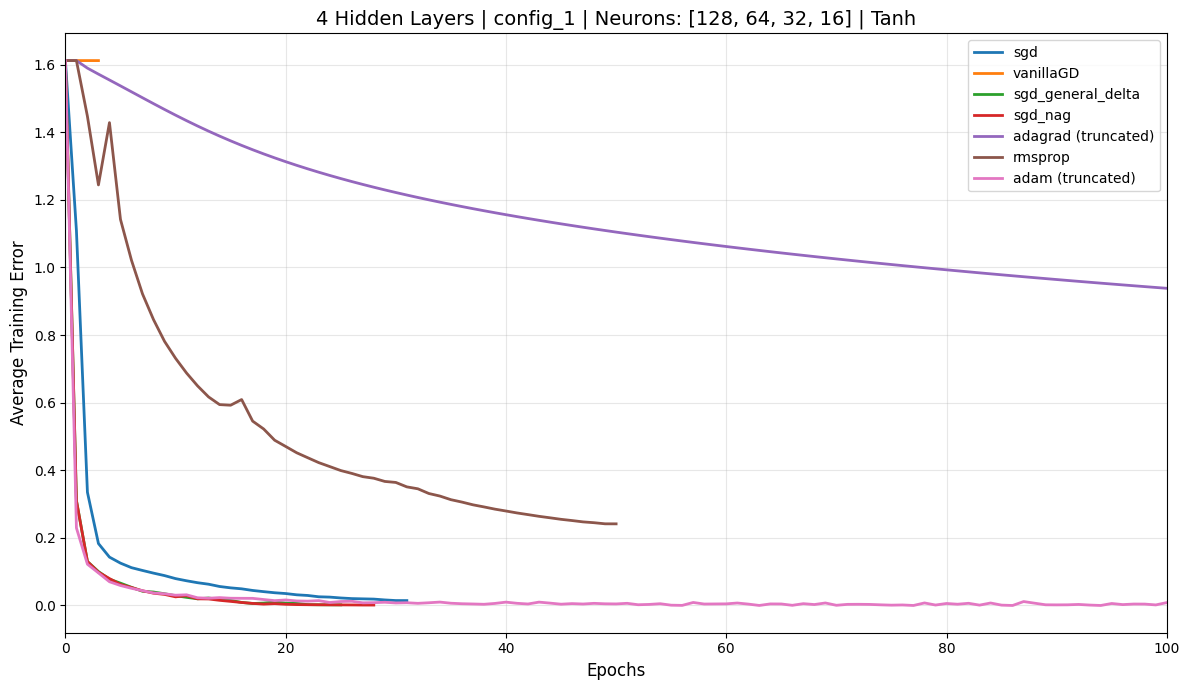

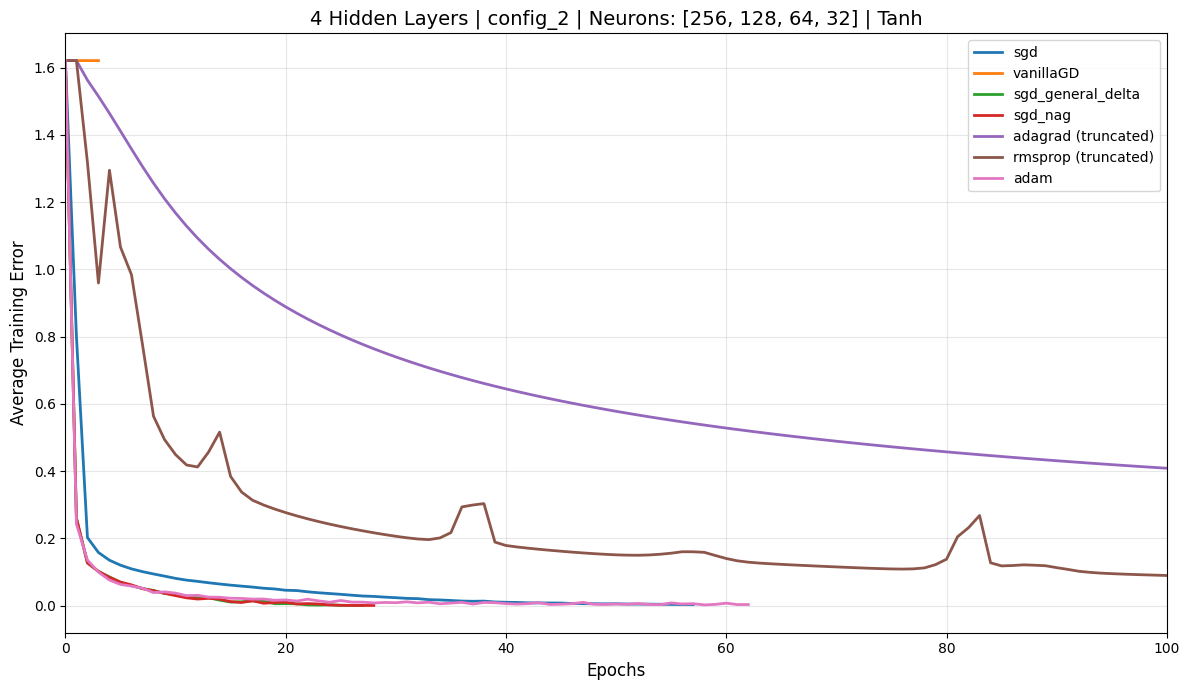

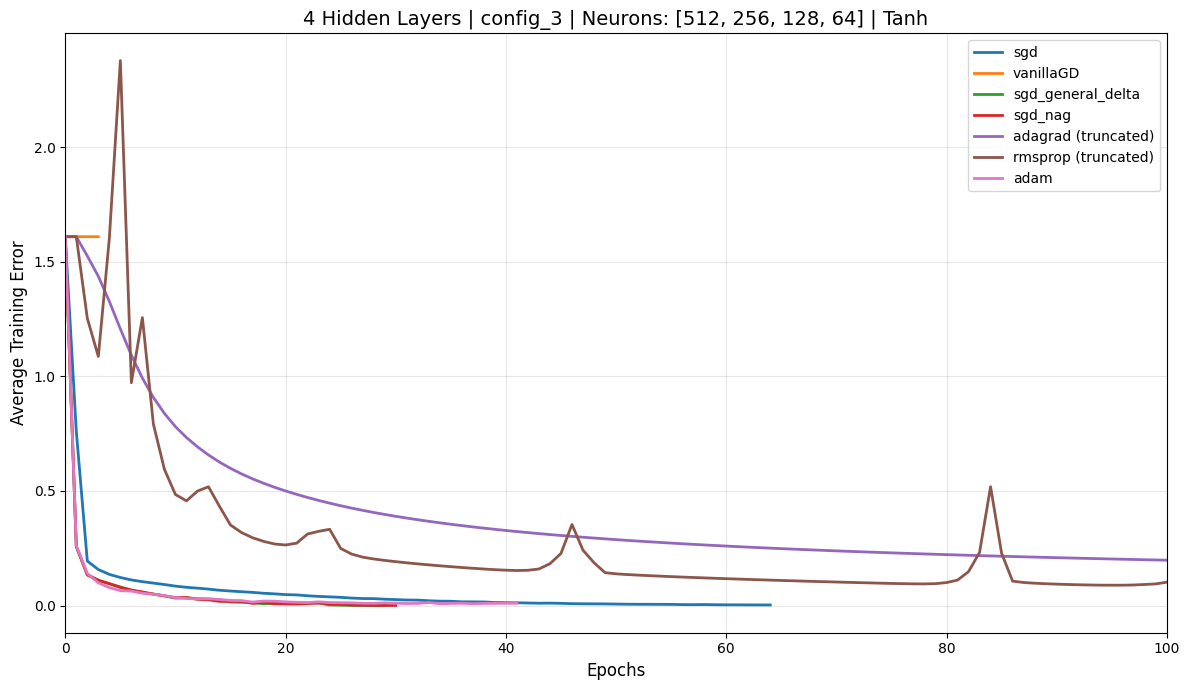

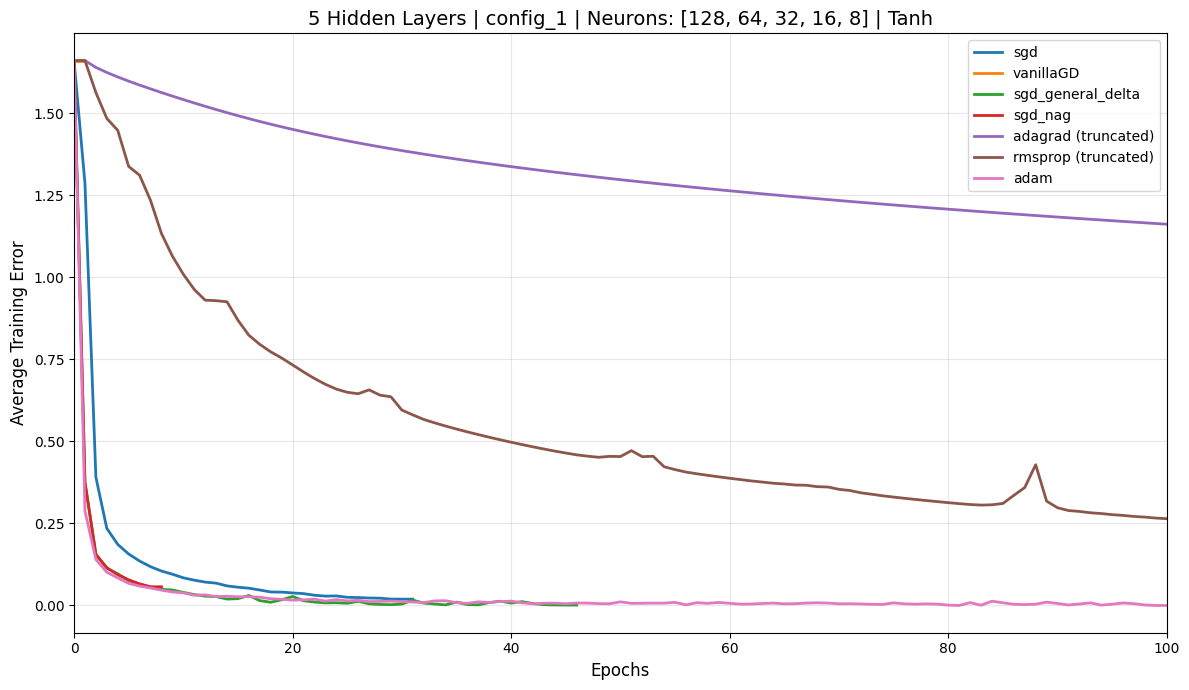

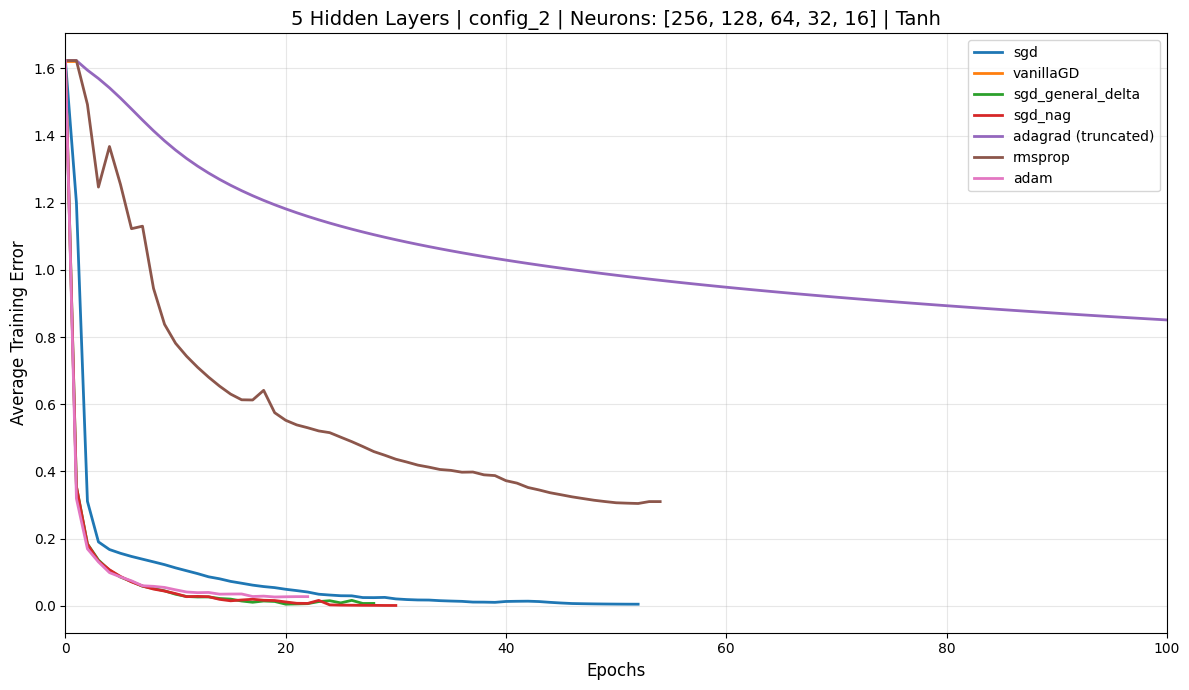

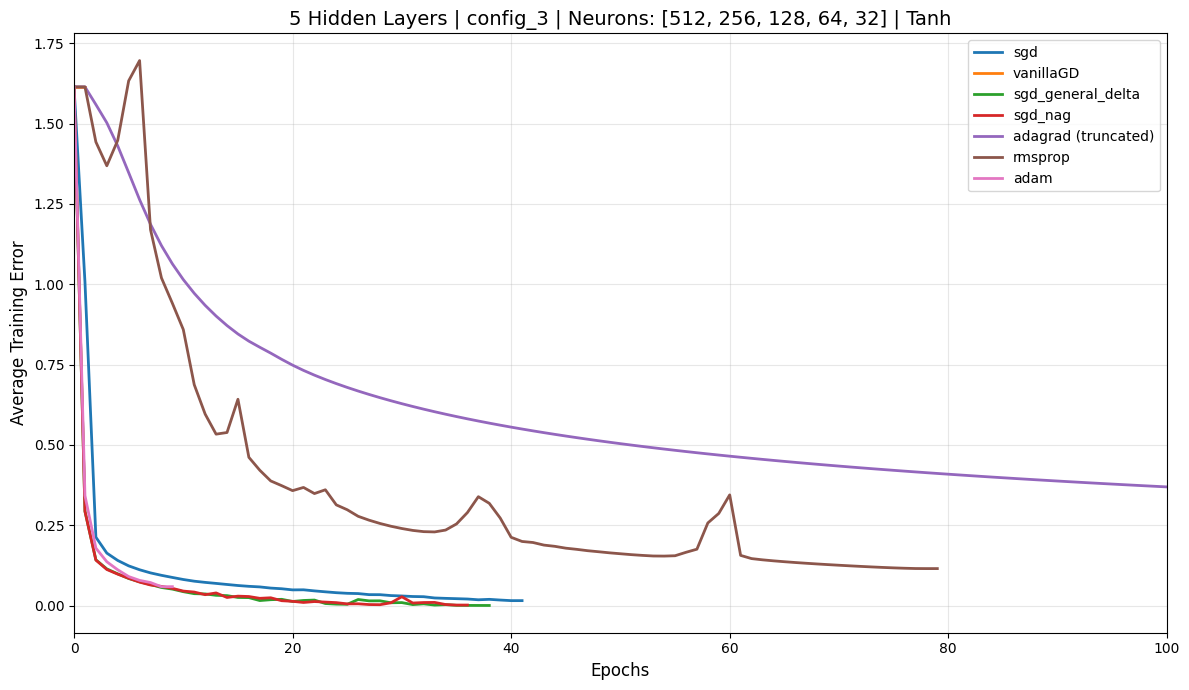


TRAINING ERROR PLOTS GENERATED SUCCESSFULLY
Maximum displayed epochs: 100
Figures saved to: training_error_plots/


In [50]:
# ============================================================
# TRAINING ERROR PLOTS
# ============================================================
#
# errors structure:
#
# errors[0] = initial error BEFORE training
# errors[1] = error AFTER epoch 1
# errors[2] = error AFTER epoch 2
# ...
#
# Therefore:
#
# Epoch 0 -> errors[0]
# Epoch 1 -> errors[1]
# Epoch 2 -> errors[2]
#
# The complete JSON histories are NOT modified.
# PLOT_MAX_EPOCHS only controls visualization.
# ============================================================


# ============================================================
# PLOT SETTINGS
# ============================================================

PLOT_MAX_EPOCHS = 100

FIGURE_DIR = "training_error_plots"

# SAVE_PNG = False
# SAVE_PDF = False
SAVE_PNG = True
SAVE_PDF = True

FIGURE_DPI = 300


# ============================================================
# CREATE OUTPUT DIRECTORY
# ============================================================

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)


# ============================================================
# TRAINING ERROR PLOTS
# ============================================================

for architecture in ARCHITECTURES_TO_LOAD:

    # --------------------------------------------------------
    # Find an available optimizer
    # --------------------------------------------------------

    available_optimizers = [
        optimizer_name
        for optimizer_name in OPTIMIZER_NAMES
        if optimizer_name in all_results[architecture]
    ]

    if len(available_optimizers) == 0:

        print(
            f"No results found for "
            f"{architecture} hidden layers."
        )

        continue


    first_optimizer = available_optimizers[0]


    configurations = all_results[
        architecture
    ][
        first_optimizer
    ][
        "configurations"
    ]


    # ========================================================
    # EACH CONFIGURATION
    # ========================================================

    for config_name, config_info in configurations.items():

        hidden_nodes = config_info[
            "hidden_nodes"
        ]


        plt.figure(
            figsize=(12, 7)
        )


        # ====================================================
        # PLOT EACH OPTIMIZER
        # ====================================================

        for optimizer_name in OPTIMIZER_NAMES:

            if optimizer_name not in all_results[
                architecture
            ]:
                continue


            optimizer_data = all_results[
                architecture
            ][
                optimizer_name
            ]


            if config_name not in optimizer_data[
                "configurations"
            ]:
                continue


            errors = np.array(
                optimizer_data[
                    "configurations"
                ][
                    config_name
                ][
                    "errors"
                ],
                dtype=float
            )


            # ------------------------------------------------
            # TOTAL TRAINING EPOCHS
            # ------------------------------------------------

            total_epochs = len(errors) - 1


            # ------------------------------------------------
            # VISUALIZATION LIMIT
            # ------------------------------------------------

            epochs_to_plot = min(
                total_epochs,
                PLOT_MAX_EPOCHS
            )


            # ------------------------------------------------
            # IMPORTANT:
            #
            # Include epoch 0!
            #
            # Epoch 0 = initial error
            # Epoch 1 = after epoch 1
            # ...
            # ------------------------------------------------

            epoch_numbers = np.arange(
                0,
                epochs_to_plot + 1
            )


            error_values = errors[
                :epochs_to_plot + 1
            ]


            # ------------------------------------------------
            # Legend label
            # ------------------------------------------------

            label_text = optimizer_name

            if total_epochs > PLOT_MAX_EPOCHS:

                label_text += f" (truncated)"


            # ------------------------------------------------
            # Plot
            # ------------------------------------------------

            plt.plot(
                epoch_numbers,
                error_values,
                linewidth=2,
                label=label_text
            )


        # ====================================================
        # AXES
        # ====================================================

        plt.xlabel(
            "Epochs",
            fontsize=12
        )

        plt.ylabel(
            "Average Training Error",
            fontsize=12
        )


        plt.title(
            f"{architecture} Hidden Layers | "
            f"{config_name} | "
            f"Neurons: {hidden_nodes} | "
            f"Tanh",
            fontsize=14
        )


        # ====================================================
        # X-AXIS
        # ====================================================

        plt.xlim(
            0,
            PLOT_MAX_EPOCHS
        )


        # ====================================================
        # GRID
        # ====================================================

        plt.grid(
            True,
            alpha=0.3
        )


        # ====================================================
        # LEGEND
        # ====================================================

        plt.legend(
            fontsize=10,
            loc="best"
        )


        plt.tight_layout()


        # ====================================================
        # FILE NAME
        # ====================================================

        figure_base_name = (
            f"architecture_{architecture}_"
            f"{config_name}_"
            f"training_error"
        )


        # ====================================================
        # SAVE PNG
        # ====================================================

        if SAVE_PNG:

            png_path = os.path.join(
                FIGURE_DIR,
                figure_base_name + ".png"
            )

            plt.savefig(
                png_path,
                dpi=FIGURE_DPI,
                bbox_inches="tight"
            )


        # ====================================================
        # SAVE PDF
        # ====================================================

        if SAVE_PDF:

            pdf_path = os.path.join(
                FIGURE_DIR,
                figure_base_name + ".pdf"
            )

            plt.savefig(
                pdf_path,
                bbox_inches="tight"
            )


        # ====================================================
        # DISPLAY
        # ====================================================

        plt.show()

        plt.close()


print("\n" + "=" * 80)
print("TRAINING ERROR PLOTS GENERATED SUCCESSFULLY")
print("=" * 80)

print(
    f"Maximum displayed epochs: "
    f"{PLOT_MAX_EPOCHS}"
)

print(
    f"Figures saved to: "
    f"{FIGURE_DIR}/"
)

In [9]:
# ============================================================
# TRAINING + VALIDATION ACCURACY TABLE
# ============================================================

accuracy_rows = []

for architecture in ARCHITECTURES_TO_LOAD:

    for optimizer_name in OPTIMIZER_NAMES:

        if optimizer_name not in all_results[
            architecture
        ]:
            continue

        optimizer_data = all_results[
            architecture
        ][
            optimizer_name
        ]

        for config_name, config_result in optimizer_data[
            "configurations"
        ].items():

            accuracy_rows.append({

                "Hidden Layers":
                    architecture,

                "Configuration":
                    config_name,

                "Neurons":
                    str(config_result["hidden_nodes"]),

                "Optimizer":
                    optimizer_name,

                "Convergence Epochs":
                    config_result["epochs"],

                "Training Accuracy (%)":
                    config_result[
                        "final_train_accuracy"
                    ],

                "Validation Accuracy (%)":
                    config_result[
                        "final_val_accuracy"
                    ]
            })


accuracy_df = pd.DataFrame(
    accuracy_rows
)

accuracy_df = accuracy_df.sort_values(
    [
        "Hidden Layers",
        "Configuration",
        "Optimizer"
    ]
)


display(accuracy_df)

,Hidden Layers,Configuration,Neurons,Optimizer,Convergence Epochs,Training Accuracy (%),Validation Accuracy (%)
12,3,config_1,"[128, 64, 32]",adagrad,929,96.565657,95.915679
18,3,config_1,"[128, 64, 32]",adam,85,99.929732,98.181818
15,3,config_1,"[128, 64, 32]",rmsprop,116,98.006148,96.811594
0,3,config_1,"[128, 64, 32]",sgd,53,99.991217,97.707510
6,3,config_1,"[128, 64, 32]",sgd_general_delta,22,100.000000,98.366271
...,...,...,...,...,...,...,...
59,5,config_3,"[512, 256, 128, 64, 32]",rmsprop,79,97.198068,96.337286
44,5,config_3,"[512, 256, 128, 64, 32]",sgd,41,99.648661,97.048748
50,5,config_3,"[512, 256, 128, 64, 32]",sgd_general_delta,38,100.000000,98.181818
53,5,config_3,"[512, 256, 128, 64, 32]",sgd_nag,36,99.956083,98.208169


In [11]:
# ============================================================
# ACCURACY TABLES FOR EACH ARCHITECTURE
# ============================================================

for architecture in ARCHITECTURES_TO_LOAD:

    temp = accuracy_df[
        accuracy_df["Hidden Layers"] == architecture
    ].copy()

    print("\n")
    print("=" * 110)
    print(
        f"ARCHITECTURE: {architecture} HIDDEN LAYERS"
    )
    print("=" * 110)

    display(
        temp[
            [
                "Configuration",
                "Neurons",
                "Optimizer",
                "Convergence Epochs",
                "Training Accuracy (%)",
                "Validation Accuracy (%)"
            ]
        ]
    )



ARCHITECTURE: 3 HIDDEN LAYERS


,Configuration,Neurons,Optimizer,Convergence Epochs,Training Accuracy (%),Validation Accuracy (%)
12,config_1,"[128, 64, 32]",adagrad,929,96.565657,95.915679
18,config_1,"[128, 64, 32]",adam,85,99.929732,98.181818
15,config_1,"[128, 64, 32]",rmsprop,116,98.006148,96.811594
0,config_1,"[128, 64, 32]",sgd,53,99.991217,97.707510
6,config_1,"[128, 64, 32]",sgd_general_delta,22,100.000000,98.366271
9,config_1,"[128, 64, 32]",sgd_nag,24,100.000000,98.208169
3,config_1,"[128, 64, 32]",vanillaGD,3,19.938516,20.000000
13,config_2,"[256, 128, 64]",adagrad,610,97.329820,96.205534
19,config_2,"[256, 128, 64]",adam,78,99.982433,98.234519
16,config_2,"[256, 128, 64]",rmsprop,154,98.541941,97.048748




ARCHITECTURE: 4 HIDDEN LAYERS


,Configuration,Neurons,Optimizer,Convergence Epochs,Training Accuracy (%),Validation Accuracy (%)
33,config_1,"[128, 64, 32, 16]",adagrad,1872,98.076416,96.811594
39,config_1,"[128, 64, 32, 16]",adam,126,100.000000,98.260870
36,config_1,"[128, 64, 32, 16]",rmsprop,50,96.117699,95.546772
21,config_1,"[128, 64, 32, 16]",sgd,31,98.032499,95.942029
27,config_1,"[128, 64, 32, 16]",sgd_general_delta,25,99.982433,98.445323
30,config_1,"[128, 64, 32, 16]",sgd_nag,28,99.982433,98.260870
24,config_1,"[128, 64, 32, 16]",vanillaGD,3,20.000000,20.000000
34,config_2,"[256, 128, 64, 32]",adagrad,915,98.225736,96.758893
40,config_2,"[256, 128, 64, 32]",adam,62,99.824330,97.891963
37,config_2,"[256, 128, 64, 32]",rmsprop,155,98.533158,97.048748




ARCHITECTURE: 5 HIDDEN LAYERS


,Configuration,Neurons,Optimizer,Convergence Epochs,Training Accuracy (%),Validation Accuracy (%)
54,config_1,"[128, 64, 32, 16, 8]",adagrad,2200,98.331137,96.811594
60,config_1,"[128, 64, 32, 16, 8]",adam,100,100.000000,98.076416
57,config_1,"[128, 64, 32, 16, 8]",rmsprop,254,99.341238,97.496706
42,config_1,"[128, 64, 32, 16, 8]",sgd,31,99.718928,97.285903
48,config_1,"[128, 64, 32, 16, 8]",sgd_general_delta,46,99.982433,98.076416
51,config_1,"[128, 64, 32, 16, 8]",sgd_nag,8,98.928415,97.575758
45,config_1,"[128, 64, 32, 16, 8]",vanillaGD,1,20.000000,20.000000
55,config_2,"[256, 128, 64, 32, 16]",adagrad,1785,99.323671,97.233202
61,config_2,"[256, 128, 64, 32, 16]",adam,22,99.306105,97.602108
58,config_2,"[256, 128, 64, 32, 16]",rmsprop,54,93.412385,93.438735


In [12]:
# ============================================================
# VALIDATION ACCURACY MATRIX
# ============================================================

validation_pivot = accuracy_df.pivot_table(
    index=[
        "Hidden Layers",
        "Configuration",
        "Neurons"
    ],
    columns="Optimizer",
    values="Validation Accuracy (%)"
)

display(
    validation_pivot.round(4)
)

Optimizer                                            adagrad     adam  \
Hidden Layers Configuration Neurons                                     
3             config_1      [128, 64, 32]            95.9157  98.1818   
              config_2      [256, 128, 64]           96.2055  98.2345   
              config_3      [512, 256, 128]          96.4954  98.0237   
4             config_1      [128, 64, 32, 16]        96.8116  98.2609   
              config_2      [256, 128, 64, 32]       96.7589  97.8920   
              config_3      [512, 256, 128, 64]      96.2319  98.2609   
5             config_1      [128, 64, 32, 16, 8]     96.8116  98.0764   
              config_2      [256, 128, 64, 32, 16]   97.2332  97.6021   
              config_3      [512, 256, 128, 64, 32]  96.0211  97.6548   

Optimizer                                            rmsprop      sgd  \
Hidden Layers Configuration Neurons                                     
3             config_1      [128, 64, 32]            96.8116  97.7075   
              config_2      [256, 128, 64]           97.0487  97.3913   
              config_3      [512, 256, 128]          97.3123  97.5231   
4             config_1      [128, 64, 32, 16]        95.5468  95.9420   
              config_2      [256, 128, 64, 32]       97.0487  97.3650   
              config_3      [512, 256, 128, 64]      97.0487  97.3913   
5             config_1      [128, 64, 32, 16, 8]     97.4967  97.2859   
              config_2      [256, 128, 64, 32, 16]   93.4387  97.5231   
              config_3      [512, 256, 128, 64, 32]  96.3373  97.0487   

Optimizer                                            sgd_general_delta  \
Hidden Layers Configuration Neurons                                      
3             config_1      [128, 64, 32]                      98.3663   
              config_2      [256, 128, 64]                     97.8920   
              config_3      [512, 256, 128]                    98.0501   
4             config_1      [128, 64, 32, 16]                  98.4453   
              config_2      [256, 128, 64, 32]                 98.0764   
              config_3      [512, 256, 128, 64]                97.9974   
5             config_1      [128, 64, 32, 16, 8]               98.0764   
              config_2      [256, 128, 64, 32, 16]             97.8920   
              config_3      [512, 256, 128, 64, 32]            98.1818   

Optimizer                                            sgd_nag  vanillaGD  
Hidden Layers Configuration Neurons                                      
3             config_1      [128, 64, 32]            98.2082    20.0000  
              config_2      [256, 128, 64]           98.0764    19.6838  
              config_3      [512, 256, 128]          97.9447    92.7536  
4             config_1      [128, 64, 32, 16]        98.2609    20.0000  
              config_2      [256, 128, 64, 32]       98.0764    20.0000  
              config_3      [512, 256, 128, 64]      98.0237    20.0000  
5             config_1      [128, 64, 32, 16, 8]     97.5758    20.0000  
              config_2      [256, 128, 64, 32, 16]   98.2082    20.0000  
              config_3      [512, 256, 128, 64, 32]  98.2082    20.0000

In [13]:
# ============================================================
# BEST ARCHITECTURE BASED ON VALIDATION ACCURACY
# ============================================================

best_per_architecture = (
    accuracy_df
    .groupby("Hidden Layers")
    ["Validation Accuracy (%)"]
    .max()
    .sort_values(
        ascending=False
    )
)

print("=" * 80)
print("BEST VALIDATION ACCURACY BY ARCHITECTURE")
print("=" * 80)

display(
    best_per_architecture.round(4)
)


# ============================================================
# CHOOSE BEST ARCHITECTURE
# ============================================================

best_architecture = (
    best_per_architecture
    .idxmax()
)

best_architecture_accuracy = (
    best_per_architecture
    .loc[best_architecture]
)


print(
    f"Best Architecture: "
    f"{best_architecture} hidden layers"
)

print(
    f"Best Validation Accuracy: "
    f"{best_architecture_accuracy:.4f}%"
)

BEST VALIDATION ACCURACY BY ARCHITECTURE


,Validation Accuracy (%)
Hidden Layers,
4,98.4453
3,98.3663
5,98.2082


Best Architecture: 4 hidden layers
Best Validation Accuracy: 98.4453%


In [14]:
# ============================================================
# BEST CONFIGURATION + OPTIMIZER WITHIN BEST ARCHITECTURE
# ============================================================

best_architecture_rows = accuracy_df[
    accuracy_df["Hidden Layers"] ==
    best_architecture
]

best_run = (
    best_architecture_rows
    .sort_values(
        "Validation Accuracy (%)",
        ascending=False
    )
    .iloc[0]
)


print("=" * 80)
print("BEST RUN")
print("=" * 80)

print(
    f"Architecture      : "
    f"{best_run['Hidden Layers']} hidden layers"
)

print(
    f"Configuration     : "
    f"{best_run['Configuration']}"
)

print(
    f"Neurons           : "
    f"{best_run['Neurons']}"
)

print(
    f"Optimizer         : "
    f"{best_run['Optimizer']}"
)

print(
    f"Epochs            : "
    f"{best_run['Convergence Epochs']}"
)

print(
    f"Training Accuracy : "
    f"{best_run['Training Accuracy (%)']:.4f}%"
)

print(
    f"Validation Accuracy: "
    f"{best_run['Validation Accuracy (%)']:.4f}%"
)

BEST RUN
Architecture      : 4 hidden layers
Configuration     : config_1
Neurons           : [128, 64, 32, 16]
Optimizer         : sgd_general_delta
Epochs            : 25
Training Accuracy : 99.9824%
Validation Accuracy: 98.4453%


In [16]:
import os
import copy
import json
import numpy as np
import random
import torch
from torch import nn
from torch.utils.data import DataLoader
from torch.optim import SGD, Adam, Adagrad, RMSprop
from torchvision import datasets, transforms

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("Using CPU")


def build_model(hidden_nodes):

    layers = [nn.Flatten()]

    for i in range(len(hidden_nodes)):

        if i == 0:
            layers.append(
                nn.Linear(784, hidden_nodes[i])
            )
        else:
            layers.append(
                nn.Linear(
                    hidden_nodes[i - 1],
                    hidden_nodes[i]
                )
            )

        layers.append(nn.Tanh())

    layers.append(
        nn.Linear(hidden_nodes[-1], 5)
    )

    return nn.Sequential(*layers)

Using CPU


In [20]:
data_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

train_data = datasets.ImageFolder(
    'Group_16/train',
    transform=data_transforms
)

val_data = datasets.ImageFolder(
    'Group_16/val',
    transform=data_transforms
)

test_data = datasets.ImageFolder(
    'Group_16/test',
    transform=data_transforms
)

print(train_data.class_to_idx)
print(val_data.class_to_idx)
print(test_data.class_to_idx)

assert train_data.class_to_idx == val_data.class_to_idx
assert train_data.class_to_idx == test_data.class_to_idx

print("Class mapping verified:", train_data.class_to_idx)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Test samples:", len(test_data))

image, label = train_data[0]

print("Image shape:", image.shape)

{'1': 0, '5': 1, '6': 2, '7': 3, '9': 4}
{'1': 0, '5': 1, '6': 2, '7': 3, '9': 4}
{'1': 0, '5': 1, '6': 2, '7': 3, '9': 4}
Class mapping verified: {'1': 0, '5': 1, '6': 2, '7': 3, '9': 4}
Training samples: 11385
Validation samples: 3795
Test samples: 3795
Image shape: torch.Size([1, 28, 28])


In [17]:
# ============================================================
# LOAD BEST MODEL
# ============================================================
BEST_MODEL_PATH = (
    "model_4_sgd_general_delta_config_1.pth"
)

best_hidden_nodes = [
    128,
    64,
    32,
    16
]

best_model = build_model(
    best_hidden_nodes
)

best_model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

best_model = best_model.to(device)

best_model.eval()

print(
    "Best model loaded successfully."
)

print(
    "Architecture:",
    best_hidden_nodes
)


Best model loaded successfully.
Architecture: [128, 64, 32, 16]


In [21]:
from sklearn.metrics import confusion_matrix
import numpy as np
# ============================================================
# CONFUSION MATRIX + PREDICTIONS
# ============================================================

def get_predictions(model, data):

    loader = DataLoader(
        data,
        batch_size=128,
        shuffle=False,
        pin_memory=(device.type == "cuda")
    )

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for x, y in loader:

            x = x.to(
                device,
                non_blocking=True
            )

            output = model(x)

            predictions = torch.argmax(
                output,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                y.numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions)
    )

In [22]:
# ============================================================
# TEST EVALUATION
# ============================================================

test_labels, test_predictions = (
    get_predictions(
        best_model,
        test_data
    )
)


# ============================================================
# TEST ACCURACY
# ============================================================

test_accuracy = (
    100 *
    np.mean(
        test_labels ==
        test_predictions
    )
)


# ============================================================
# TEST CONFUSION MATRIX
# ============================================================

test_cm = confusion_matrix(
    test_labels,
    test_predictions
)


class_names = [
    "1",
    "5",
    "6",
    "7",
    "9"
]


print("=" * 80)
print("TEST RESULTS — BEST ARCHITECTURE")
print("=" * 80)

print(
    f"Test Classification Accuracy: "
    f"{test_accuracy:.4f}%"
)

print("\nTest Confusion Matrix:")
print(test_cm)

TEST RESULTS — BEST ARCHITECTURE
Test Classification Accuracy: 98.1291%

Test Confusion Matrix:
[[749   5   1   4   0]
 [  2 744   4   1   8]
 [  1  10 747   0   1]
 [  3   1   2 744   9]
 [  2   6   1  10 740]]


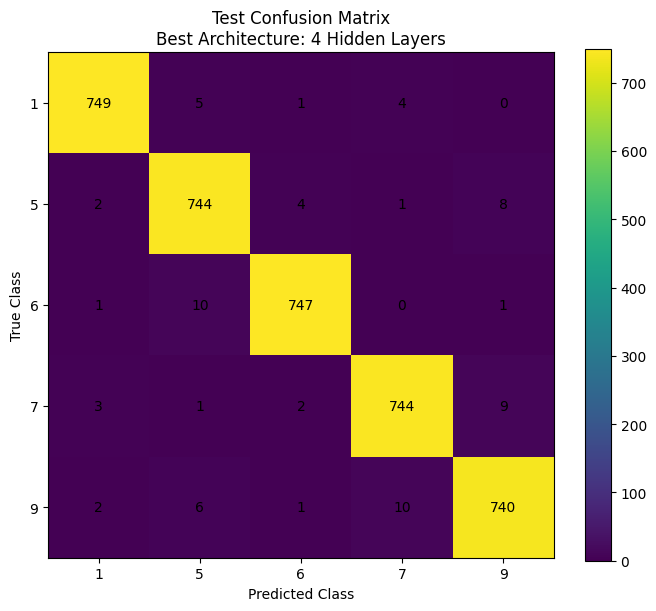

In [23]:
# ============================================================
# PLOT TEST CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(7, 6))

plt.imshow(test_cm)

plt.colorbar()

plt.xticks(
    range(len(class_names)),
    class_names
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.title(
    "Test Confusion Matrix\n"
    "Best Architecture: 4 Hidden Layers"
)


# ------------------------------------------------------------
# Write values inside cells
# ------------------------------------------------------------

for i in range(
    test_cm.shape[0]
):

    for j in range(
        test_cm.shape[1]
    ):

        plt.text(
            j,
            i,
            test_cm[i, j],
            ha="center",
            va="center"
        )


plt.tight_layout()

plt.show()

In [24]:
# ============================================================
# TRAINING EVALUATION
# ============================================================

train_labels, train_predictions = (
    get_predictions(
        best_model,
        train_data
    )
)


# ============================================================
# TRAINING ACCURACY
# ============================================================

train_accuracy = (
    100 *
    np.mean(
        train_labels ==
        train_predictions
    )
)


# ============================================================
# TRAINING CONFUSION MATRIX
# ============================================================

train_cm = confusion_matrix(
    train_labels,
    train_predictions
)


print("=" * 80)
print("TRAINING RESULTS — BEST ARCHITECTURE")
print("=" * 80)

print(
    f"Training Classification Accuracy: "
    f"{train_accuracy:.4f}%"
)

print("\nTraining Confusion Matrix:")
print(train_cm)

TRAINING RESULTS — BEST ARCHITECTURE
Training Classification Accuracy: 99.9824%

Training Confusion Matrix:
[[2276    0    0    1    0]
 [   0 2277    0    0    0]
 [   0    0 2277    0    0]
 [   0    0    0 2277    0]
 [   0    0    0    1 2276]]


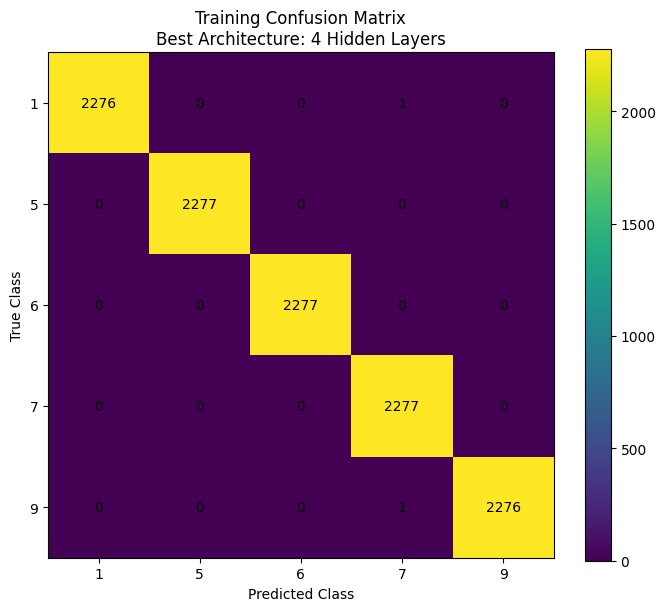

In [25]:
# ============================================================
# PLOT TRAINING CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(7, 6))

plt.imshow(train_cm)

plt.colorbar()

plt.xticks(
    range(len(class_names)),
    class_names
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.title(
    "Training Confusion Matrix\n"
    "Best Architecture: 4 Hidden Layers"
)


for i in range(
    train_cm.shape[0]
):

    for j in range(
        train_cm.shape[1]
    ):

        plt.text(
            j,
            i,
            train_cm[i, j],
            ha="center",
            va="center"
        )


plt.tight_layout()

plt.show()

In [26]:
# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 100)
print("FINAL ASSIGNMENT SUMMARY")
print("=" * 100)

print(
    f"Best Architecture        : "
    f"{best_architecture} hidden layers"
)

print(
    f"Best Configuration       : "
    f"{best_run['Configuration']}"
)

print(
    f"Hidden Layer Nodes       : "
    f"{best_run['Neurons']}"
)

print(
    f"Best Optimizer           : "
    f"{best_run['Optimizer']}"
)

print(
    f"Convergence Epochs       : "
    f"{int(best_run['Convergence Epochs'])}"
)

print(
    f"Training Accuracy        : "
    f"{train_accuracy:.4f}%"
)

print(
    f"Validation Accuracy      : "
    f"{best_run['Validation Accuracy (%)']:.4f}%"
)

print(
    f"Test Accuracy            : "
    f"{test_accuracy:.4f}%"
)

print("\n")
print("Training Confusion Matrix:")
print(train_cm)

print("\n")
print("Test Confusion Matrix:")
print(test_cm)

print("=" * 100)



FINAL ASSIGNMENT SUMMARY
Best Architecture        : 4 hidden layers
Best Configuration       : config_1
Hidden Layer Nodes       : [128, 64, 32, 16]
Best Optimizer           : sgd_general_delta
Convergence Epochs       : 25
Training Accuracy        : 99.9824%
Validation Accuracy      : 98.4453%
Test Accuracy            : 98.1291%


Training Confusion Matrix:
[[2276    0    0    1    0]
 [   0 2277    0    0    0]
 [   0    0 2277    0    0]
 [   0    0    0 2277    0]
 [   0    0    0    1 2276]]


Test Confusion Matrix:
[[749   5   1   4   0]
 [  2 744   4   1   8]
 [  1  10 747   0   1]
 [  3   1   2 744   9]
 [  2   6   1  10 740]]
